Chris McCarthy

Professor Hua

DSC630-T302 Predictive Analytics

Final Course Project

1. Introduction

The electric vehicle market has exploded in popularity over the past 15 years. While there are a number of factors at play, many of which will be explored in this research paper, the general consensus is consumers and manufacturers are prioritizing sustainability and energy efficiency. As EV (electric vehicle) adoption continues to expand, driving range is one of the most important factors when it comes to consumer behavior and purchasing an EV. Buyers want to be certain they are getting the most potential driving distance possible when considering an EV, and because of this, it is a key factor in business success.

Since driving range is a major player in EV viability, this exploration will seek to understand not only the impact of driving range itself, but also factors that may contribute to range performance. While larger batteries are generally associated with longer range, other factors like vehicle efficiency, torque, and segment/class (body type and size: luxury vs mini) can influence the distance an EV can travel on a single charging session.

The purpose of this research project is to identify factors that most strongly influence driving range. It is also to evaluate the effectiveness of regression modeling for predicting range. EDA (exploratory data analysis) and predictive modeling will both be used to determine relationships between vehicle specifications and driving range.

2. Driving Questions

1. Which vehicle characteristics are most strongly associated with electric vehicle driving range?

2. Can battery capacity alone accurately predict driving range?

3. Does a multiple linear regression model improve predictive performance compared to a simple linear regression model?

4. How do vehicle segment and manufacturer characteristics relate to driving range performance?

3. Overview of Data Used

This exploration uses the data set 'electric_vehicles_spec_2025.csv'

The dataset has modern and up-to-date information on a variety of EV specifications. These include: battery capacity, energy efficiency, torque, top speed, acceleration, vehicle segment, and estimated driving range.

The target variable selected for this research is 'range_km.' This represents the driving range of select EVs in kilometers. Predictor variables being examined throughout the project will include battery_capacity_kWh, efficiency_wh_per_km, torque_nm, and vehicle segment.

Data preparation included inspection for missing values, duplicate records, and checking the consistency of data types. Variables considered irrelevant to the research were removed. Categorical variables (such as vehicle segment) were encoded to allow for regression modeling.

4. Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#load
df = pd.read_csv("data/electric_vehicles_spec_2025.csv")

#preview
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478 entries, 0 to 477
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   brand                      478 non-null    object 
 1   model                      477 non-null    object 
 2   top_speed_kmh              478 non-null    int64  
 3   battery_capacity_kWh       478 non-null    float64
 4   battery_type               478 non-null    object 
 5   number_of_cells            276 non-null    float64
 6   torque_nm                  471 non-null    float64
 7   efficiency_wh_per_km       478 non-null    int64  
 8   range_km                   478 non-null    int64  
 9   acceleration_0_100_s       478 non-null    float64
 10  fast_charging_power_kw_dc  477 non-null    float64
 11  fast_charge_port           477 non-null    object 
 12  towing_capacity_kg         452 non-null    float64
 13  cargo_volume_l             477 non-null    object 

In [2]:
#checking for missing values
df.isnull().sum()

brand                          0
model                          1
top_speed_kmh                  0
battery_capacity_kWh           0
battery_type                   0
number_of_cells              202
torque_nm                      7
efficiency_wh_per_km           0
range_km                       0
acceleration_0_100_s           0
fast_charging_power_kw_dc      1
fast_charge_port               1
towing_capacity_kg            26
cargo_volume_l                 1
seats                          0
drivetrain                     0
segment                        0
length_mm                      0
width_mm                       0
height_mm                      0
car_body_type                  0
source_url                     0
dtype: int64

The dataset is mostly complete in terms of information. There are 7 variables with missing values. The highest is number_of_cells with 202 missing. Additional missing values are towing_capacity_kg at 26, torque_nm 7, model 1, fast_charge_power_kw_dc 1, fast_charge_port 1 and cargo_volume_l at 1.

In [3]:
print("Rows before cleaning:", len(df))

df_clean = df.dropna(
    subset=[
        'battery_capacity_kWh',
        'efficiency_wh_per_km',
        'torque_nm',
        'segment',
        'range_km'
    ]
)

print("Rows after cleaning:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Rows before cleaning: 478
Rows after cleaning: 471
Rows removed: 7


In the end, the only variable relevant to this exploration that needed to be addressed was torque_nm. As such, 7 rows were removed in order to clean the data.

5. Exploratory Data Analysis

This section will go over all of the visuals used in the exploration of the subject.

Distribution of Driving Range

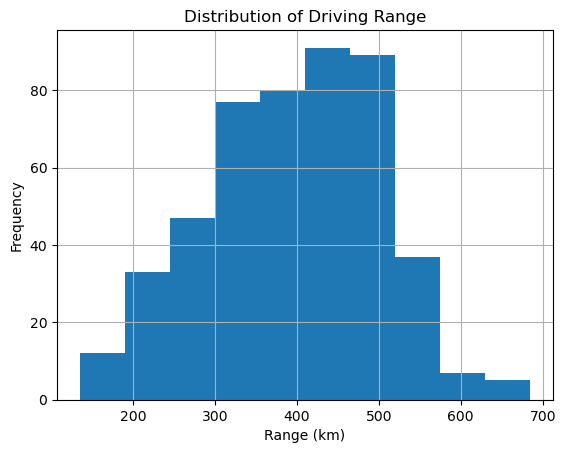

In [4]:
plt.figure()
df['range_km'].hist()
plt.title("Distribution of Driving Range")
plt.xlabel("Range (km)")
plt.ylabel("Frequency")
plt.show()

The histogram shows that driving range is normally distributed. Most vehicles fall between 300 km and 500 km. There are fewer vehicles on the low and high ends (sub 300 or above 500). Overall, this means manufacturers cluster around mid-range performance levels.

Distribution of Battery Capacity

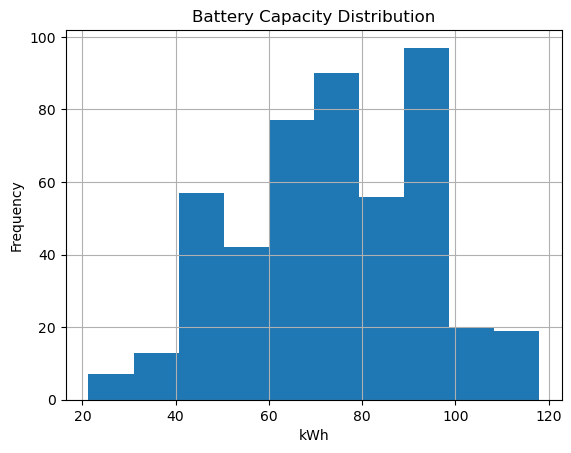

In [5]:
plt.figure()
df['battery_capacity_kWh'].hist()
plt.title("Battery Capacity Distribution")
plt.xlabel("kWh")
plt.ylabel("Frequency")
plt.show()

The distribution of battery capacity across vehicles is slightly right-skewed. Most vehicles have battery capacities between 50 and 100 kWh. There are few vehicles on the low and high ends. Overall, battery capacity will perform between the 50-100 kWh range.

Relationship of Battery Capacity vs Driving Range

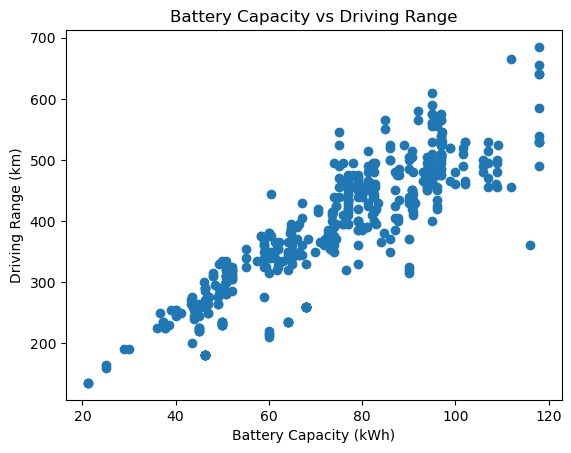

In [6]:
plt.figure()
plt.scatter(df['battery_capacity_kWh'], df['range_km'])
plt.xlabel("Battery Capacity (kWh)")
plt.ylabel("Driving Range (km)")
plt.title("Battery Capacity vs Driving Range")
plt.show()

The scatter plot shows a strong positive linear relationship between battery capacity and driving range. This is encouraging because my driving question focuses on this relationship in particular. The visual supports the notion that battery capacity is a primary predictor of driving range.

Relationship of Efficiency vs Driving Range

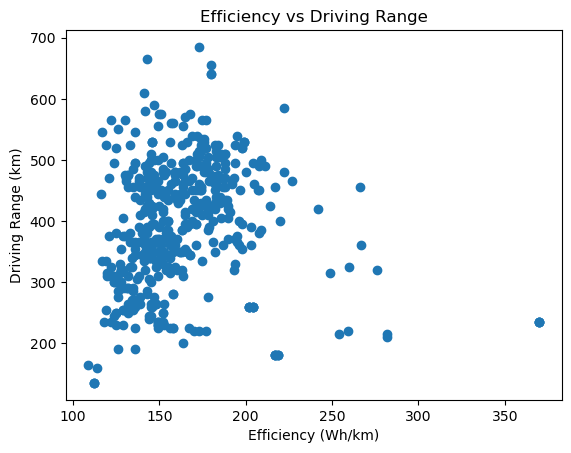

In [7]:
plt.figure()
plt.scatter(df['efficiency_wh_per_km'], df['range_km'])
plt.xlabel("Efficiency (Wh/km)")
plt.ylabel("Driving Range (km)")
plt.title("Efficiency vs Driving Range")
plt.show()

The relationship between efficiency and driving range appears less positively linear than battery capacity and driving range. There is clustering visible, but because there is a lack of a strong linear trend, it suggests efficiency alone is not as strong a predictor of range. It is likely efficiency contributes to performance but is heavily dependent on or overshadowed by battery capacity itself.

Average Range by Manufacturer

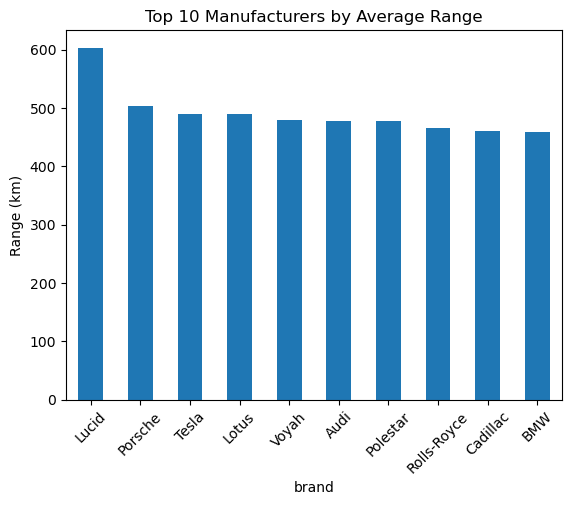

In [8]:
top_brands = df.groupby('brand')['range_km'].mean().sort_values(ascending=False).head(10)

top_brands.plot(kind='bar')
plt.title("Top 10 Manufacturers by Average Range")
plt.ylabel("Range (km)")
plt.xticks(rotation=45)
plt.show()

The bar chart offers insight on average driving range of electric vehicles based on brand. The top 3 brands are Lucid, Porsche and Tesla. This suggests the manufacturers produce vehicles with better driving range than their competitors. Overall, the differences between brands is fairly moderate, indicating a fairly competitive market.

This visualization is included because it offers differences between manufacturers. However, it will not be included in the predictive modeling portion of this project. It could be useful for a future exploration but as of now, will be excluded in favor of features that more directly impact driving range.

Average Range by Segment

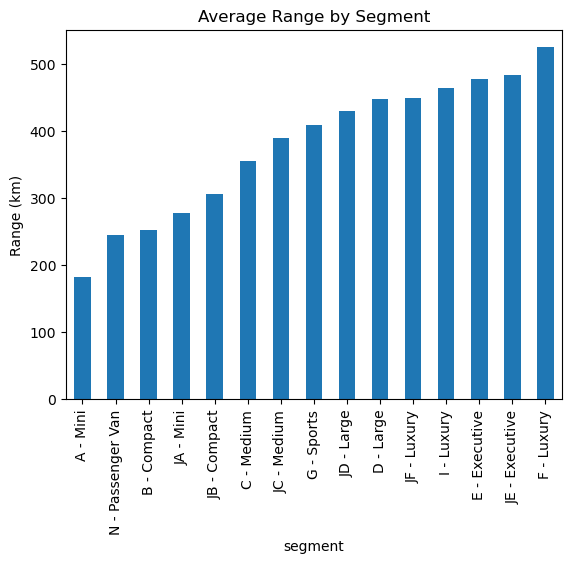

In [9]:
df.groupby('segment')['range_km'].mean().sort_values().plot(kind='bar')
plt.title("Average Range by Segment")
plt.ylabel("Range (km)")
plt.show()

The vehicle segments bar chart shows a clear trend of larger and more premium segments having higher average driving ranges. This suggests size and class are important factors to consider for driving range, likely due to larger segments having batteries with greater capacities. I will explore this further to discern the exact average difference in battery capacities between large and mini segments.

Correlation Heatmap

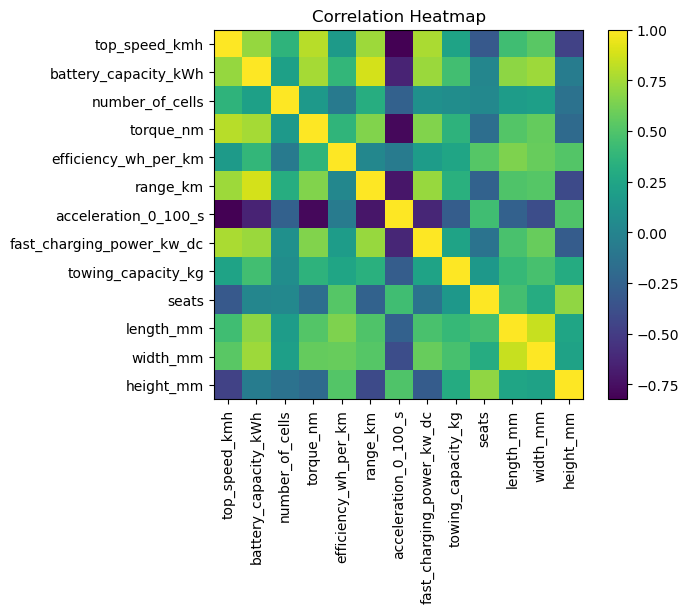

In [10]:
corr = df.corr(numeric_only=True)

plt.figure()
plt.imshow(corr)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.show()

The heatmap is helpful for visualizing different factors and their respective correlations. One of the strongest positive correlations shown on the heatmap is between battery capacity and driving range. This is meaningful because it supports earlier findings and my general hypothesis that battery capacity is a primary predictor of driving range. Other honorable mentions include torque and fast charging power, both of which score around .75 for correlation with driving range.

6. Regression Modeling

Model 1 - Simple Linear Regression

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

#features and target
X = df[['battery_capacity_kWh']]
y = df['range_km']

#train and test data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

#train model
model = LinearRegression()
model.fit(X_train, y_train)

#predictions
y_pred = model.predict(X_test)

#evaluations
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R²:", r2)

RMSE: 49.040887873136754
R²: 0.7727212970874995


The output of my simple linear regression model is promising. The sole predictor being evaluated in relation to driving range is battery capacity. The R2 is .77, meaning battery capacity explains around 77% of variance in driving range. This is a solid start. Additionally, the RMSE is 49 km. This suggests predictions by the model will fall within 49 km of expected range. I would like to improve on this margin.

Encoding for 'Segment' for use in Multiple Linear Regression

In [12]:
#variables for multiple linear regression
model_df = df[
    [
        'battery_capacity_kWh',
        'efficiency_wh_per_km',
        'torque_nm',
        'segment',
        'range_km'
    ]
].dropna()

#one-hot encode segment
model_df = pd.get_dummies(
    model_df,
    columns=['segment'],
    drop_first=True
)

model_df.head()

,battery_capacity_kWh,efficiency_wh_per_km,torque_nm,range_km,segment_B - Compact,segment_C - Medium,segment_D - Large,segment_E - Executive,segment_F - Luxury,segment_G - Sports,segment_I - Luxury,segment_JA - Mini,segment_JB - Compact,segment_JC - Medium,segment_JD - Large,segment_JE - Executive,segment_JF - Luxury,segment_N - Passenger Van
0,37.8,156,235.0,225,True,False,False,False,False,False,False,False,False,False,False,False,False,False
1,37.8,149,235.0,225,True,False,False,False,False,False,False,False,False,False,False,False,False,False
2,50.8,158,345.0,280,False,False,False,False,False,False,False,False,True,False,False,False,False,False
3,50.8,158,345.0,280,False,False,False,False,False,False,False,False,True,False,False,False,False,False
4,60.0,156,310.0,315,False,False,False,False,False,False,False,False,False,True,False,False,False,False


Model 2 - Multiple Linear Regression

In [13]:
#features and target
X = model_df.drop('range_km', axis=1)
y = model_df['range_km']

#train and test data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

#build and train model
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

#predictions
y_pred = multi_model.predict(X_test)

#evaluations
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R²:", r2)

RMSE: 25.840313694740235
R²: 0.926630989557124


The multiple linear regression model has improved on the simple version. The R2 is now .926, or approximately 93%. This is great because the model can account for 93% of variance in driving range. Also, the RMSE is now 25.84 km, or roughly 26 km. The model margin of error improved from 49 km down to 26 km. This is great improvement, and suggests that while battery capacity is the strongest individual factor influencing driving range, additional vehicle features improve predictive performance.

Coefficients

In [14]:
#coefficients
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': multi_model.coef_
})

coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

,Feature,Coefficient
5,segment_D - Large,79.002550
7,segment_F - Luxury,72.723698
6,segment_E - Executive,67.549056
14,segment_JE - Executive,45.350961
8,segment_G - Sports,44.589533
4,segment_C - Medium,41.705505
12,segment_JC - Medium,37.305941
10,segment_JA - Mini,37.051449
13,segment_JD - Large,22.765060
11,segment_JB - Compact,21.960753


The coefficients output still maintains a positive relationship between battery capacity and driving range. This is good because my hypothesis continues to be supported. Torque and efficiency are much more minor within the context of the multiple linear regression model. However, segment shows strong positive coefficients, especially the large, luxury and executive classes. This indicates to me that these models are likely equipped with larger batteries, improved engineering, or other advantanges related to EV range performance as a result of the price point.

One surprising result is the negative coefficient associated with efficiency. However, after considering the way the dataset measures efficiency, I realized it uses Wh/km, which represents energy consumed per kilometer traveled. This means higher Wh/km values indicate greater energy consumption and lower vehicle efficiency. Because less efficient vehicles tend to achieve lower driving ranges, the negative coefficient is logically consistent with real-world EV performance.

7. Further Model Diagnostics based on Feedback

Actual vs Predicted Plot

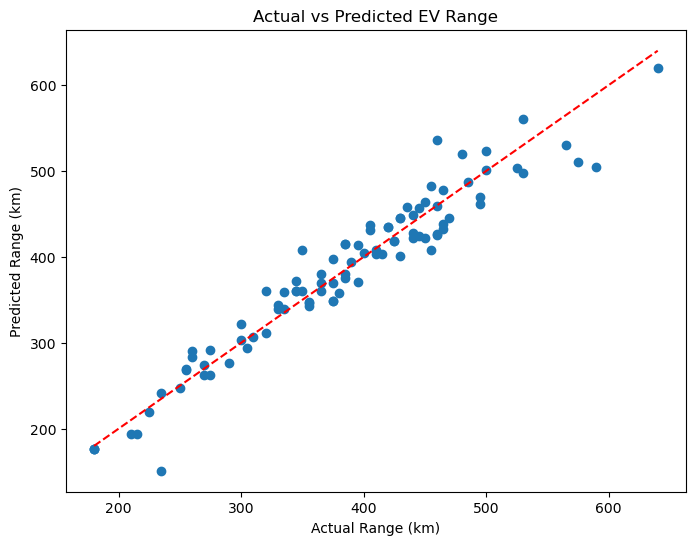

In [17]:
#actual vs predicted plot

import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual Range (km)')
plt.ylabel('Predicted Range (km)')
plt.title('Actual vs Predicted EV Range')

plt.show()

The visual output for actual vs predicted compares observed vehicle ranges with values predicted by the multiple linear regression model. As seen here, most values are close to the diagonal reference line, indicating parity between actual and predicted values. This is in line with the model's high R2 value of .927, and suggests the model is capable of producing accurate range predictions across a wide number of different electric vehicles.

Residual Plot

In [18]:
#calculate residuals

residuals = y_test - y_pred

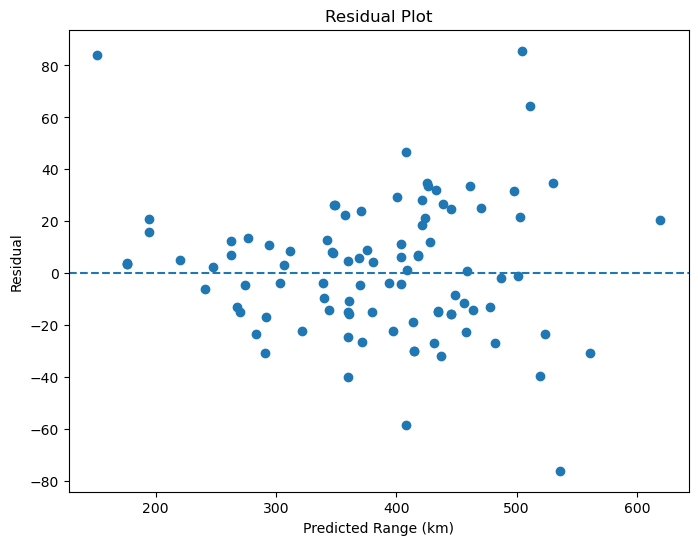

In [22]:
#plot

plt.figure(figsize=(8,6))

plt.scatter(y_pred, residuals)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel('Predicted Range (km)')
plt.ylabel('Residual')
plt.title('Residual Plot')

plt.show()

In [23]:
#residual statistics

print("Mean Residual:", residuals.mean())
print("Standard Deviation:", residuals.std())

Mean Residual: 1.4465987830256863
Standard Deviation: 25.93665986823645


Residual analysis was also performed to gauge model error patterns and the difference between actual and predicted vehicle range values. Since the residuals appear to be randomly distributed around 0 without an obvious patterning, the assumptions of the linear regression are likely satisfied within reasonable doubt. The lack of an obvious trend indicates the model is operating with little bias.

Additionally, statistics related to residuals were generated. The model has a mean residual of 1.45km, which suggests the model does not over or underpredict vehicle range. The mean residual's closeness to 0 further supports the notion the model is largely unbiased.

Also, the standard deviation is 25.9 which is nearly identical to the RMSE of 25.8. This means the prediction errors are minute, and is supportive of the model's predictive performance.

8. Results and Findings

The goal of this research project is to determine primary factors that influence range_km of EVs. The primary hypothesis posits battery_capacity as the strongest predictor, followed by efficiency, torque and vehicle segment. After exploratory data analysis and regression modeling, battery capacity is supported as the most important predictor of electric vehicle driving range. Based on the simple linear regression, battery capacity on its own explains roughly 77.3% of variations in driving range.

The multiple linear regression model improved on the simple linear regression by including efficiency, torque and vehicle segment. The model output improved substantially at an R2 of .927. It also reduced RMSE from 49km to 26km. This combination of vehicle characteristics were a significant improvement in terms of predictive performance.

Additionally, coefficient analysis was performed. This analysis revealed battery capacity as the strongest positive influence on driving range. Also of note, efficiency showed a meaningful negative relationship due to increased energy consumption per kilometer. Vehicle segment was also impactful, contributing to predictive performance based on design and vehicle class. The luxury and larger models had bigger positive impacts on driving range, suggesting those models have improved technology, efficiency, and/or battery capacities compared to their smaller counterparts.

Finally, residual analysis was performed to determine how much bias was in the model. The mean residual was only 1.45km, which is negligible and in support of a low to unbiased model. The standard deviation is also in line with the RMSE from before at approximately 26km, which supports the model's predictive accuracy. Overall, the research project has been successful in identifying meaningful positive factors on driving range of EVs.

9. Conclusion

The purpose of this project is to identify factors most strongly influencing electric vehicle driving range and to evaluate the predictive performance of regression modeling techniques. Using exploratory data analysis and predictive modeling, the research questions were successfully addressed. The findings demonstrated battery capacity as the strongest predictor of EV range_km, which is in line with the original hypothesis. The other factors also provided meaningful predictive value, as seen in the output of the multiple linear regression model. Overall, the multiple linear regression model performed the best with an R2 of .927.

The business application of these findings is for both consumers and manufacturers. For potential buyers (consumers), battery capacity is the most important factor when considering vehicle specifications, especially if driving range is the primary goal. For manufacturers, the findings of this project reinforce the importance of battery design and energy efficiency for maximizing driving range. It also supports the notion that vehicle segment plays a role. The ability to predict driving range using the handful of features selected for simple and multiple linear regression modeling supports the usefulness of a data-driven approach in understanding EV performance.

In regards to limitations, there is one primary limitation for consumers to consider: driving conditions. All analysis here relies on manufacturer-reported vehicle specifications as opposed to real-world data. What this means for buyers is the potential for external conditions to change expected outcomes. Factors such as weather conditions, terrain, driving behavior and battery degradation are outside of this project analysis. A next step for this exploration could be the research and inclusion of such variables for a more comprehensive understanding of electric vehicle range.

Overall, this project was successful in predicting driving range using vehicle specifications with a high degree of accuracy. As EV adoption continues to grow, predictive analytics will be a valuable tool for understanding how these different technological factors influence EV performance. This will pave the way for both consumers and manufacturers to make better informed decisions regarding purchasing and design.

10. References

https://www.kaggle.com/datasets/urvishahir/electric-vehicle-specifications-dataset-2025

Professor Hua (feedback)

Applied Predictive Analytics: Principles and Techniques for the Professional Data Analyst by Wiley (course material)